# Foundation models for amortized inference

_Authors: Stefan T. Radev, Paul Christian-Bürkner, Jonas Arruda_

## The two problems in amortized Bayesian inference

Amortized Bayesian inference tries to solve two problems at the same time: **representation learning** and **probabilistic inference**. The former is a means to an end. The latter is our end goal.

In BayesFlow, we make a conceptual distinction between these two problems at the level of the neural architecture. Accordingly, our estimators typically consist of a **summary network** (sometimes called an embedding network) and an **inference network**, although they can sometimes get blurred in composite architectures (e.g., [UNets for diffusion models](./Spatial_Data_and_Parameters.ipynb)). The summary network does the representation learning. The inference network does the inference. 

For example, to estimate a posterior distribution $p(\theta \mid x_1,\dots,x_N)$ over $N$ IID observations, we may want to train a function $s = h(x_1,\dots,x_N)$ that only retains the information necessary to estimate the posterior of $\theta$. In other words, the summary network is not an encoder in the conventional sense, as it does not need to be sufficient for the data; it only needs to be sufficient for $\theta$, that is $p(\theta \mid x_1,\dots,x_N) = p(\theta \mid s)$.

Learning informative representations for downstream inference is useful and necessary in many cases. These include:
- The data tensor varies in shape or size (e.g., the sample size $N$ varies or the data is a matrix with varying rows and columns).
- The data tensor has more dimensions than the parameter tensor (e.g., parameters are vectors but the data comprises a sequence of images and cannot be naively concatenated).
- The data tensor is too high dimensional for direct inference in likelihood estimation, that is, when the aim is to estimate $p(x \mid \theta)$.
- The data contains invariances or symmetries which need to be represented by the posterior.

In many cases, however, learning these representations can be anything but easy. We call the failure to learn useful representations a **representation gap** [1], and we've recently shown cases where suboptimal training dynamics can lead to such gaps. Additionally, when simulation budgets are tight (e.g., when working with expensive simulators) or the data dimensionality is high, a lot of engineering may need to be invested in the design of the summary network. 

>Wouldn't it be dreamy if somebody else could do the representation learning for us, while we focus on inference?

In the following, we showcase the utility of foundation models as both summary and inference components in amortized Bayes. We focus primarily on the ease with which foundation model encoders can be plugged into BayesFlow workflows as "frozen" summary networks, to which we attach an inference head. Essentially, we treat the frozen encoder as a capable feature engineer. This approach is illustrated in the figure below.

![Example workflow with foundation-model encoders and embeddings](misc/foundation/embedding_workflow.png)


In the final part of the tutorial, we demonstrate how to use a foundation model as an inference network, as explored in [2]. Both approaches have many moving parts and trade-offs, and this tutorial tries to contribute some conceptual clarity.


- [1] Olischläger, H., Jedhoff, S., Kucharský, Š., Mishra, A., Radev, S. T., & Bürkner, P. (2026). [Mitigating representation gaps in amortized Bayesian inference with auxiliary supervision](https://arxiv.org/abs/2609.39525). *arXiv preprint arXiv:2609.39525*.

- [2] Vetter, J., Gloeckler, M., Gedon, D., & Macke, J. H. (2026). [Effortless, simulation-efficient Bayesian inference using tabular foundation models](https://proceedings.neurips.cc/paper_files/paper/2025/hash/770cabd044c4eacb6dc5924d9a686dce-Abstract-Conference.html). *Advances in Neural Information Processing Systems, 38*, 82685-82724.

## How does a foundation model connect to BayesFlow?

Foundation models typically consist of an encoder and a decoder. The encoder supplies data representations (called embeddings or hidden states) that the encoder uses to generate an output of a given modality (e.g., text, images, tabular entries). Encoder-only and decoder-only models can also extract data embeddings, even though these can be more difficult to localize in the architecture. We can distinguish the following approaches.

| Approach | BayesFlow input | What is trained? | Used here? |
|---|---|---|---|
| Cached hidden states as a direct condition | Cached `inference_conditions` | Inference network | TabPFN example |
| Cached hidden states through a summary network | Cached `summary_variables` | Small summary network and inference network | Chronos-2 example |
| Frozen encoder called during training | Raw `summary_variables` | Inference network; encoder stays frozen | Not used |
| Fine-tuned encoder | Raw `summary_variables` | Selected encoder layers and inference network | Not used |

The first two rows differ only in whether BayesFlow learns an additional summary network. A summary network can adapt a large embedding to the inference task, but it cannot reconstruct information already removed by the frozen encoder.

Backend compatibility matters only when the encoder is called inside the trainable BayesFlow model. A wrapped PyTorch encoder requires the Torch backend and a differentiable tensor path. In this notebook the encoders run separately and return cached NumPy arrays, so BayesFlow can use any automatically detected Keras backend.

> Note: A frozen encoder should run in evaluation mode and without gradient tracking. Fine-tuning instead requires training mode for the selected layers and must avoid NumPy conversion between the encoder and BayesFlow.

## How to extract an embedding

The original task head answers the foundation model's pretraining task. It produces a forecast, class probability, regression distribution, or generated token. That output can be low-dimensional and may discard information about simulator parameters. We therefore want hidden features immediately before the task head, obtained through a documented embedding method or the base encoder API.

For every foundation model, we have to:

1. Identify the original task head and the hidden tensor that feeds it.
2. Check the meaning of every tensor axis: rows, time steps, channels, patches, or tokens.
3. Remove padding or task-specific tokens with the documented mask.
4. Pool only axes that should be exchangeable; preserve identities such as channel or feature order when they carry information.
5. Retain normalization statistics when location or scale may depend on the simulator parameters.
6. Confirm the resulting shape, then test the embedding through parameter recovery and calibration.

The two concrete extraction points used below are consistent:

| Encoder | Task head we bypass | Embedding we extract |
|---|---|---|
| [TabPFN v2](https://github.com/PriorLabs/TabPFN) | Tabular predictive distribution | Design-weighted moments of the context-row hidden features from `get_embeddings(..., data_source="train")`, together with the response mean and scale. |
| [Chronos-2](https://huggingface.co/amazon/chronos-2) | Forecasting output | Context encoder tokens from `embed`; pool time tokens separately by channel and retain normalization statistics. |

### Aside: Using pretrained encoders from Hugging Face

The [Hugging Face Hub](https://huggingface.co/models) provides pretrained encoders that can be used to extract features from high-dimensional observations, such as images. For example, we can load a pretrained DINOv2 vision encoder and use it to obtain fixed-size vectors:

```python
import numpy as np
import torch
from transformers import AutoImageProcessor, AutoModel

# Load a pretrained image encoder
checkpoint = "facebook/dinov2-small"
processor = AutoImageProcessor.from_pretrained(checkpoint)
encoder = AutoModel.from_pretrained(checkpoint).eval()

# Example batch of image observations (replace with simulated data)
images = np.random.randint(0, 256, (4, 224, 224, 3), dtype=np.uint8)

# Extract embeddings
inputs = processor(images=list(images), return_tensors="pt")
with torch.no_grad():
    embeddings = encoder(**inputs).last_hidden_state[:, 0, :].numpy()

print(embeddings.shape)  # (4, 384)
```

The resulting embeddings provide a 384-dimensional representation of each image and can be used as conditioning variables for amortized inference in BayesFlow. The encoder (or parts thereof) can be used offline or fine-tuned together with an inference head.

## Setup

Install the BayesFlow repository and the two external model packages before starting the notebook. From the repository root:

```bash
uv pip install -e .
uv pip install "tabpfn==9.2.0" "chronos-forecasting==2.3.2" "transformers>=4.41,<6"
```

Transformers is listed explicitly because the example above imports it directly. The first run also needs internet access to download the public model checkpoints; subsequent runs use the local model cache. The foundation models use CUDA when available. Their outputs are converted to NumPy before BayesFlow sees them, so no manual Keras-backend selection is needed in this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import bayesflow as bf
import keras

from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion

INFO:bayesflow:Multiple Keras-compatible backends detected (JAX, PyTorch, TensorFlow). Defaulting to JAX.
To override, set the KERAS_BACKEND environment variable before importing bayesflow.
See: https://keras.io/getting_started/#configuring-your-backend


INFO:bayesflow:Using backend 'jax'


In [2]:
rng = np.random.default_rng(2026)

device = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=["#287D8E", "#D58B40", "#596A85"]),
})

## 1. TabPFN: nonlinear regression with unequal noise

We use the model from the [generalized linear models tutorial](Bayesian_GLM.ipynb), now with a pretrained encoder. Each dataset has 100 rows and two predictors. We keep the design matrix fixed across simulations and observations. The response has a sinusoidal effect, an interaction, and noise that increases with the second predictor:

$$y_i = b + a\sin(1.5 x_{i1}) + c x_{i1}x_{i2} + 0.5x_{i2} + \epsilon_i,$$
$$\epsilon_i \sim \mathcal N\!\left(0,\,[\exp(\ell)(1+0.4|x_{i2}|)]^2\right).$$

We infer the intercept $b$, sine coefficient $a$, interaction coefficient $c$, and the log baseline noise scale $\ell$. Exponentiating $\ell$ keeps the noise scale positive; the other independent normal priors allow positive and negative effects. TabPFN will process all observed predictors and responses, while the BayesFlow inference network learns their four-parameter posterior.

We train the inference network on **4,096 simulated datasets**, compared with **384,000** (`60 × 100 × 64`) in the GLM notebook where we learned our own `SetTransformer` summary network. This results in about 94 times fewer training simulations. We want to create a more "stingy" setup, as we assume that we are now only solving an inference problem.

In [3]:
REGRESSION_PARAMETER_NAMES = ("intercept", "sine_effect", "interaction", "log_noise")

x = rng.uniform(-2, 2, size=(100, 2)).astype("float32")
prior_mean = {"intercept": 0.0, "sine_effect": 0.0, "interaction": 0.0, "log_noise": -0.5}
prior_std = {"intercept": 0.7, "sine_effect": 0.8, "interaction": 0.6, "log_noise": 0.3}


def regression_response(intercept, sine_effect, interaction, log_noise):
    mean = (
        intercept
        + sine_effect * np.sin(1.5 * x[:, 0])
        + interaction * x[:, 0] * x[:, 1]
        + 0.5 * x[:, 1]
    )
    scale = np.exp(log_noise) * (1 + 0.4 * np.abs(x[:, 1]))
    return mean + scale * rng.normal(size=mean.shape)


def simulate_regression(n):
    parameters = {
        name: rng.normal(prior_mean[name], prior_std[name], size=(n, 1)).astype("float32")
        for name in REGRESSION_PARAMETER_NAMES
    }
    return {**parameters, "y": regression_response(**parameters)}

train_raw, val_raw, test_raw = [simulate_regression(n) for n in (4096, 256, 128)]

### Compute each frozen embedding before training

[TabPFN's `fit`](https://github.com/PriorLabs/TabPFN) prepares a dataset as in-context input; it does not optimize the pretrained weights. We reuse one encoder with one ensemble member and call `fit` and `get_embeddings` for each dataset. The public method returns one hidden state $h_i$ per context row as a NumPy array, which is exactly what offline BayesFlow training needs.

The simulator mean contains an intercept and three known design terms: $\sin(1.5x_{i1})$, $x_{i1}x_{i2}$, and $x_{i2}$. For each term $z_{ik}$, we compute the design-weighted moment $N^{-1}\sum_i z_{ik}h_i$. The nonconstant design columns are centered and scaled once, and the unweighted moment uses $z_{i0}=1$. Concatenating these four moments retains signed associations between the row embeddings and the predictor design. This goes to show that some embeddings may require a bit of postprocessing before entering the inference head.

TabPFN [standardizes each dataset's response](https://github.com/PriorLabs/TabPFN/blob/main/src/tabpfn/regressor.py). We also append the response mean and standard deviation so that location and scale information remain available.

Each simulated or observed `(x, y)` pair is one complete dataset for parameter inference. After `fit(x, y)`, its 100 rows are TabPFN's context, or `train`, rows. We need hidden features for those context rows, so we request `data_source="train"`. By contrast, `data_source="test"` would return hidden features for query rows whose unknown responses TabPFN is meant to predict.

In [ ]:
tabpfn_encoder = TabPFNRegressor.create_default_for_version(
    ModelVersion.V2, 
    n_estimators=1, 
    device=device,
    fit_mode="fit_preprocessors"
)

design_basis = np.column_stack((
    np.ones(len(x)),
    np.sin(1.5 * x[:, 0]),
    x[:, 0] * x[:, 1],
    x[:, 1],
))

design_basis[:, 1:] = (
    design_basis[:, 1:] - design_basis[:, 1:].mean(axis=0)
) / design_basis[:, 1:].std(axis=0)


def tabpfn_embedding(responses):
    embeddings = []
    for y in responses:
        tabpfn_encoder.fit(x, y)
        # One query row is enough: we request the 100 context (train) embeddings.
        rows = tabpfn_encoder.get_embeddings(x[:1], data_source="train")[0]
        pooled = design_basis.T @ rows / len(x)
        embeddings.append(np.r_[pooled.ravel(), y.mean(), y.std()])

    return np.asarray(embeddings)


train, val, test = [
    {
        **{name: data[name] for name in REGRESSION_PARAMETER_NAMES},
        "embedding": tabpfn_embedding(data["y"]),
    }
    for data in (train_raw, val_raw, test_raw)
]

### Attach and train a small inference head

The BayesFlow variable slots are now as follows:
 - the cached `embedding` becomes `inference_conditions`
 - the four parameters are the `inference_variables`. 
 
Our inference head is a two-layer spline coupling flow with small subnets and dropout. BayesFlow standardizes targets and conditions using the training data. We monitor validation loss over a fixed number of epochs. Dropout is active during training, so training loss can be higher than validation loss.

In [ ]:
workflow = bf.BasicWorkflow(
    inference_variables=REGRESSION_PARAMETER_NAMES,
    inference_conditions="embedding",
    inference_network=bf.networks.CouplingFlow(
        depth=2, 
        transform="spline",
        subnet_kwargs={"widths": (128, 128), "dropout": 0.3},
    ),
    standardize="all",
    initial_learning_rate=1e-3
)

history = workflow.fit_offline(train, validation_data=val, epochs=80, batch_size=64, verbose=2)

### Loss, parameter recovery, and calibration

We can use BayesFlow's diagnostics to inspect losses, parameter recovery, and calibration on test simulations. Recovery uses posterior medians and central 90% credible intervals. The rank ECDF below each recovery plot checks calibration: systematic departures from the zero line indicate a biased or miscalibrated posterior.

INFO:bayesflow:Sampling completed in 2.49 seconds.


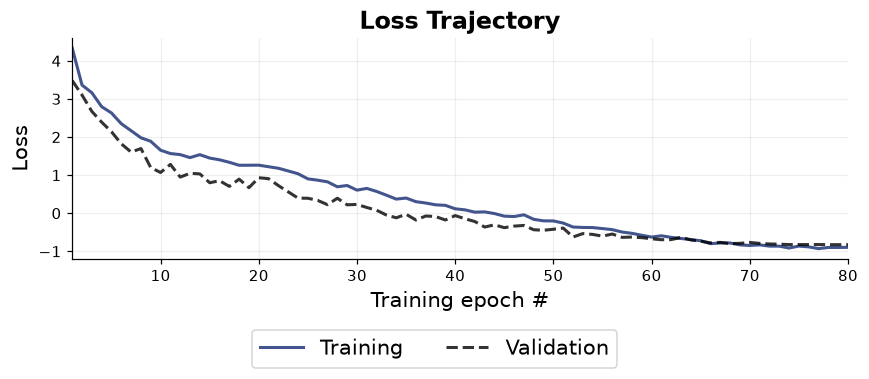

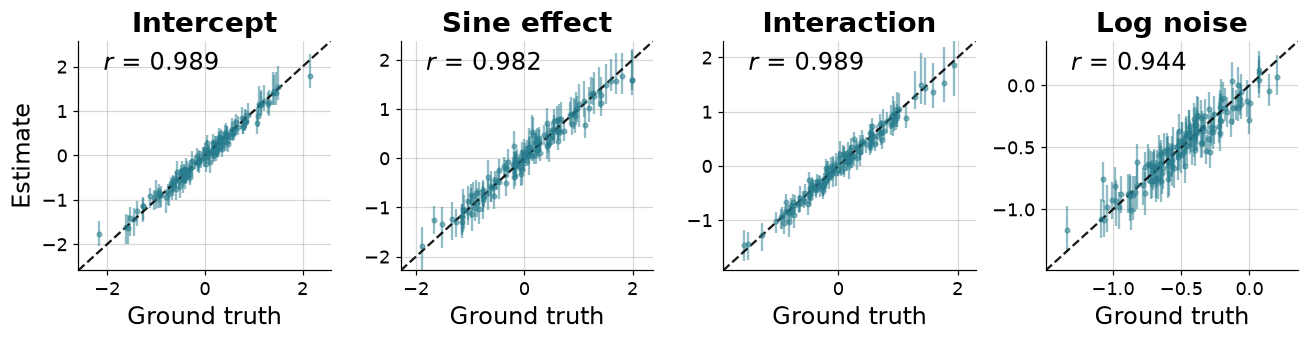

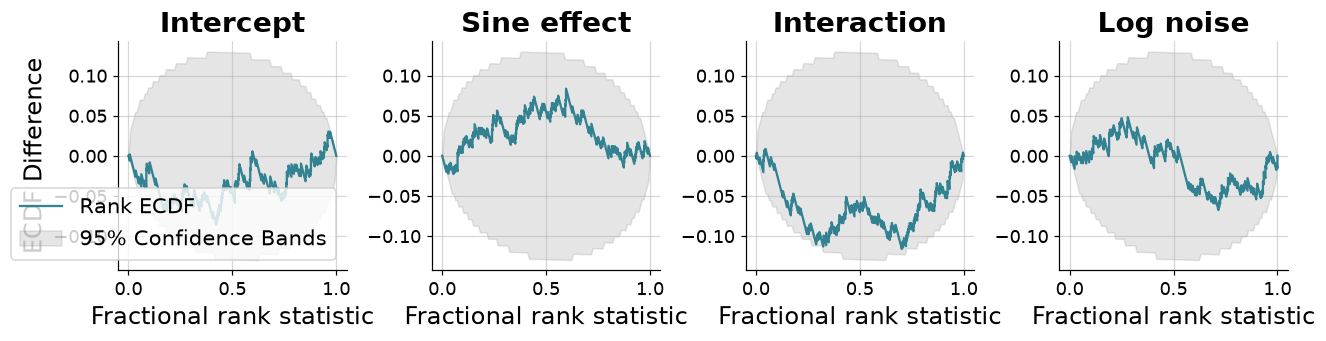

In [6]:
_ = bf.diagnostics.loss(
    history, 
    smoothing_factor=0,
    val_marker="", 
    figsize=(8, 3.5),
)

posterior_samples = workflow.sample(conditions={"embedding": test["embedding"]}, num_samples=500)

_ = bf.diagnostics.recovery(
    estimates=posterior_samples, 
    targets=test,
    variable_names=["Intercept", "Sine effect", "Interaction", "Log noise"],
    uncertainty_agg_kwargs={"prob": 0.9}, color="#287D8E",
    num_col=4, 
    figsize=(12, 3.2), 
    markersize=3
)

_ = bf.diagnostics.calibration_ecdf(
    estimates=posterior_samples, 
    targets=test,
    variable_names=["Intercept", "Sine effect", "Interaction", "Log noise"],
    difference=True, 
    num_col=4, 
    figsize=(12, 3.2), 
    rank_ecdf_color="#287D8E"
)

### Inference on a single observation

Below, we create one synthetic observed dataset so its true parameters are known. For real data, you can now replace `observed_y` with the actual observed responses on the same design. Design amortization can be achieved by varying the design matrix during training.

INFO:bayesflow:Sampling completed in 1.74 seconds.


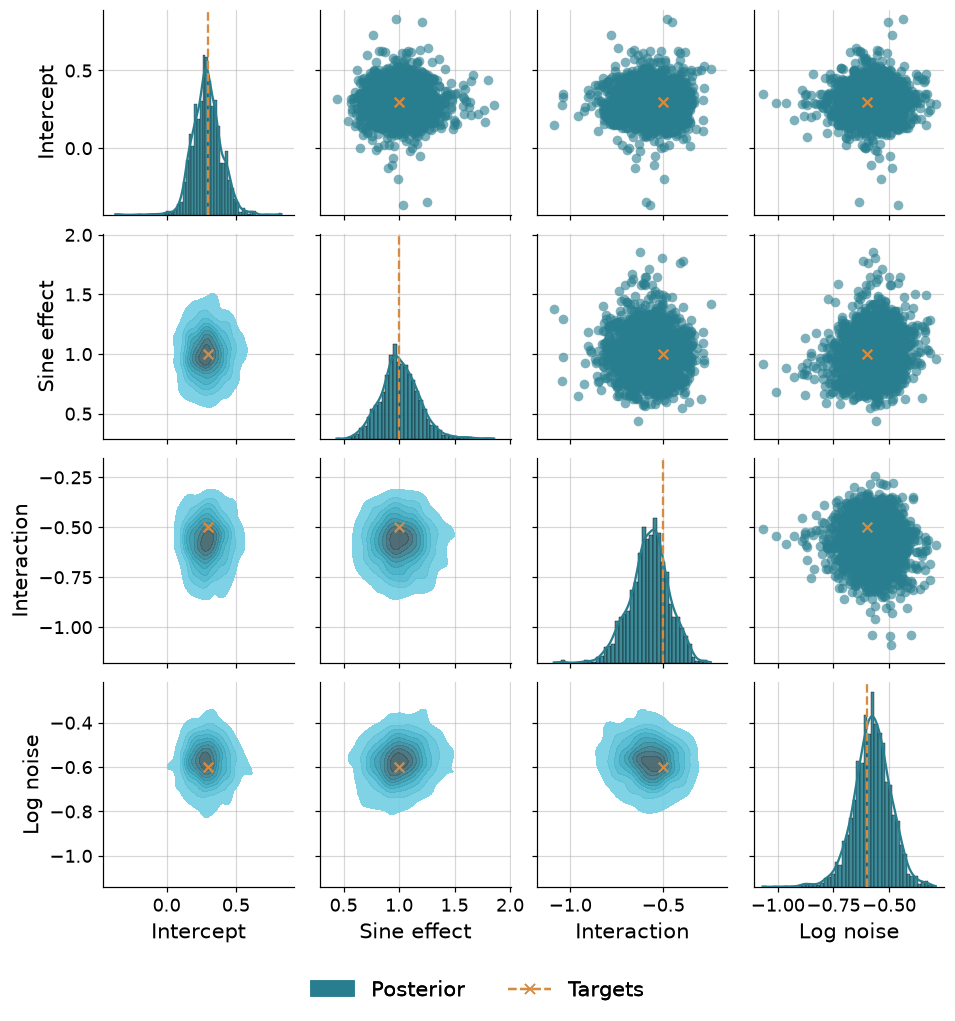

In [7]:
observed_parameters = {
    "intercept": np.array([[0.3]], dtype="float32"),
    "sine_effect": np.array([[1.0]], dtype="float32"),
    "interaction": np.array([[-0.5]], dtype="float32"),
    "log_noise": np.array([[-0.6]], dtype="float32"),
}

observed_y = regression_response(**observed_parameters)
observed_embedding = tabpfn_embedding(observed_y)

observed_posterior = workflow.sample(
    conditions={"embedding": observed_embedding}, num_samples=2000,
)

_ = bf.diagnostics.pairs_posterior(
    estimates = observed_posterior, 
    targets=observed_parameters,
    variable_names=["Intercept", "Sine effect", "Interaction", "Log noise"],
    post_color="#287D8E", 
    target_color="#D58B40",
    height=2.2, 
    place_legend_below=True
)

## 2. Chronos-2: inference on time series

The same workflow works for time series. Consider a VAR model for two coupled sequences:

$$x_t = A x_{t-1} + 0.4\epsilon_t,\qquad A = \begin{pmatrix}a_{11} & a_{12} \\ a_{21} & a_{22}\end{pmatrix},\qquad \epsilon_t\sim\mathcal N(0,I).$$

As a summary network, we will use [Chronos-2](https://huggingface.co/amazon/chronos-2), which has a public multivariate `embed` method. Its encoder can process multivariate time series, so its hidden features can contain cross-channel relationships needed to infer the off-diagonal coefficients as well as each channel's persistence.

We infer all four entries of $A$, with independent $a_{ij}\sim\mathcal U(-0.45,0.45)$. The matrix stays fixed within each dataset. Its maximum absolute row sum is below 0.9, so every prior draw is stable. Each dataset has 128 observations after a short burn-in. We use 4,096 training simulations, 512 validation simulations, and 128 test simulations.

In [8]:
VAR_PARAMETER_NAMES = ("a11", "a12", "a21", "a22")
var_names = [r"$a_{11}$", r"$a_{12}$", r"$a_{21}$", r"$a_{22}$"]


def simulate_var(a11, a12, a21, a22, n_steps=128, burn_in=64):
    matrix = np.stack((a11[:, 0], a12[:, 0], a21[:, 0], a22[:, 0]), axis=-1)
    matrix = matrix.astype("float32").reshape(-1, 2, 2)
    state = np.zeros((len(matrix), 2), dtype=np.float32)
    series = np.empty((len(matrix), 2, n_steps), dtype=np.float32)
    for t in range(n_steps + burn_in):
        innovations = rng.normal(size=state.shape).astype("float32")
        state = np.einsum("bij,bj->bi", matrix, state) + 0.4 * innovations
        if t >= burn_in:
            series[:, :, t - burn_in] = state
    return series


var_parameters = {
    name: rng.uniform(-0.45, 0.45, size=(4096 + 512 + 128, 1)).astype("float32")
    for name in VAR_PARAMETER_NAMES
}
var_prior_draws = var_parameters
var_series = simulate_var(**var_parameters)

In [ ]:
from chronos import Chronos2Pipeline

chronos = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map=device,
    dtype=torch.float32,
)
chronos.model.eval()

### Encode once, then train summary and inference networks

The [public `embed` method](https://github.com/amazon-science/chronos-forecasting/blob/main/src/chronos/chronos2/pipeline.py) accepts `(datasets, channels, time)` arrays and handles batching. It returns encoder tokens and normalization statistics on the CPU, without running the forecasting head.

We average the observed-context tokens separately for each channel, excluding the final `[REG]` and masked forecast tokens. Concatenating both channel embeddings and their location and scale statistics gives 1,540 features per dataset.

In [ ]:
def embed_var(series):
    tokens, loc_scale = chronos.embed(series, batch_size=64)
    pooled = torch.stack([item[:, :-2].mean(1).flatten() for item in tokens])
    stats = torch.stack([torch.cat(pair, dim=-1).flatten() for pair in loc_scale])
    return torch.cat((pooled, stats), dim=-1).numpy()


var_embedding = embed_var(var_series)

var_train = {
    **{name: values[:4096] for name, values in var_parameters.items()},
    "embedding": var_embedding[:4096],
}
var_validation = {
    **{name: values[4096:4608] for name, values in var_parameters.items()},
    "embedding": var_embedding[4096:4608],
}
var_test = {
    **{name: values[4608:] for name, values in var_parameters.items()},
    "embedding": var_embedding[4608:],
}

Next, we route the cached embeddings to `summary_variables`. A small `SummaryNetwork` maps them to 16 summary statistics using one 32-unit hidden layer with L2 regularization and dropout, followed by a linear output layer.

In [11]:
@bf.utils.serialization.serializable("custom")
class EmbeddingSummaryNetwork(bf.networks.SummaryNetwork):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.hidden = keras.layers.Dense(
            32, activation="swish", kernel_regularizer=keras.regularizers.L2(1e-3)
        )
        self.dropout = keras.layers.Dropout(0.5)
        self.summary_stats = keras.layers.Dense(16)

    def call(self, embeddings, training=False, **kwargs):
        hidden = self.hidden(embeddings)
        hidden = self.dropout(hidden, training=training)
        return self.summary_stats(hidden)

In [ ]:
var_adapter = bf.Adapter()
for name in VAR_PARAMETER_NAMES:
    var_adapter.constrain(name, lower=-0.45, upper=0.45)

var_adapter.concatenate(VAR_PARAMETER_NAMES, into="inference_variables")
var_adapter.rename("embedding", "summary_variables")

var_workflow = bf.BasicWorkflow(
    adapter=var_adapter,
    summary_network=EmbeddingSummaryNetwork(),
    inference_network=bf.networks.CouplingFlow(
        depth=2, 
        transform="spline",
        subnet_kwargs={"widths": (64, 64), "dropout": 0.5},
    ),
    standardize="all",
    initial_learning_rate=1e-3,
)

var_history = var_workflow.fit_offline(
    var_train, validation_data=var_validation, epochs=50, batch_size=64, verbose=2
)

INFO:bayesflow:Sampling completed in 0.55 seconds.


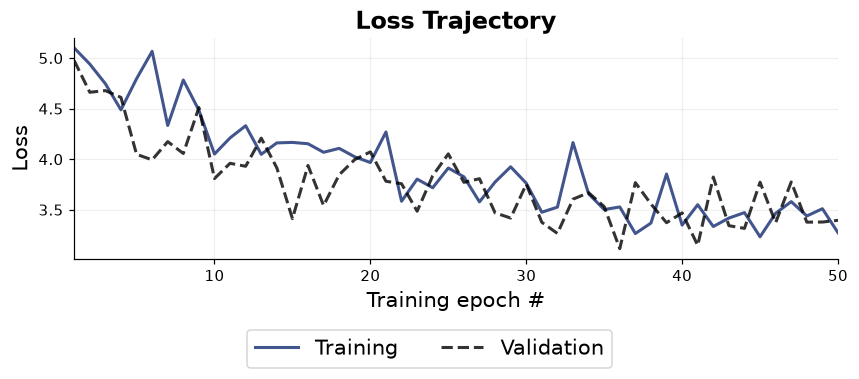

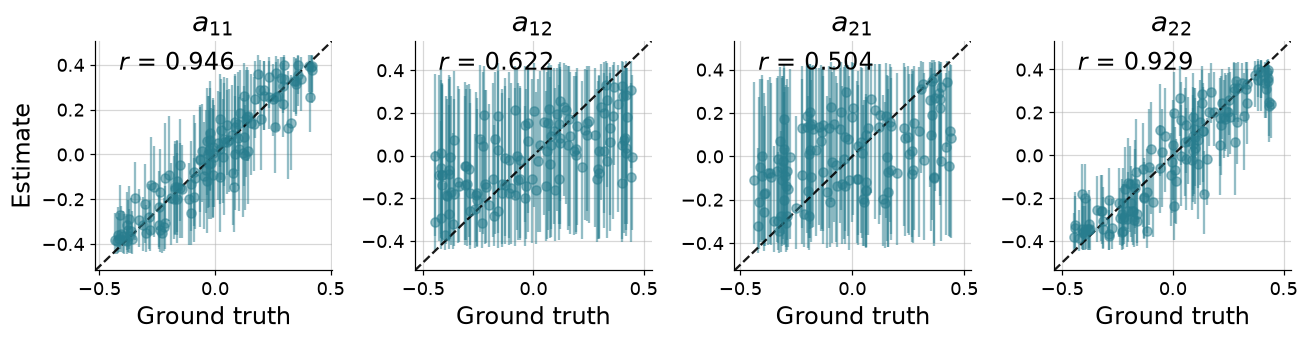

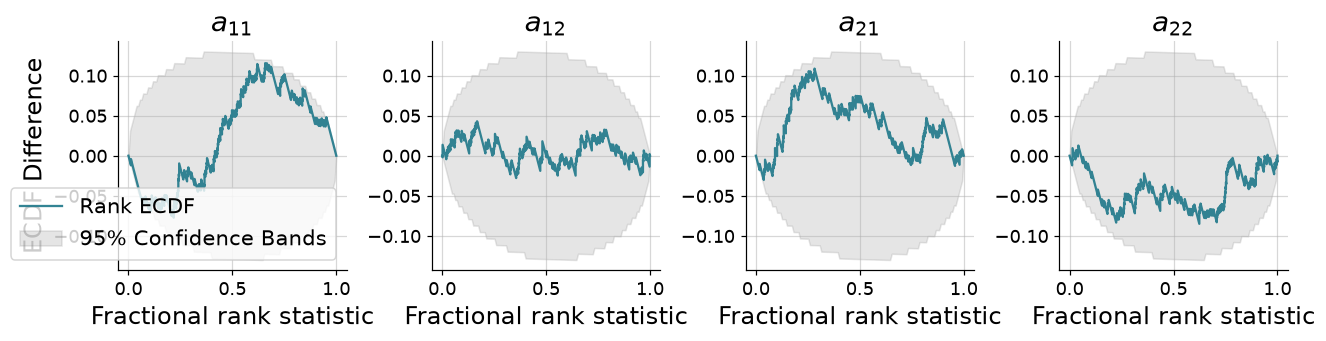

In [13]:
_ = bf.diagnostics.loss(var_history, smoothing_factor=0, val_marker="", figsize=(8, 3.5))

var_samples = var_workflow.sample(conditions={"embedding": var_test["embedding"]}, num_samples=500)

_ = bf.diagnostics.recovery(
    estimates=var_samples, 
    targets=var_test, 
    variable_names=var_names,
    uncertainty_agg_kwargs={"prob": 0.9}, 
    color="#287D8E",
    num_col=4, 
    figsize=(12, 3.2)
)

_ = bf.diagnostics.calibration_ecdf(
    estimates=var_samples, 
    targets=var_test, 
    variable_names=var_names,
    difference=True, 
    num_col=4,
    figsize=(12, 3.2), 
    rank_ecdf_color="#287D8E"
)

### Interpretation

The diagonal coefficients are recovered more reliably than the two off-diagonal coefficients. Within-channel persistence produces a strong autocorrelation signal, whereas a directional cross-channel effect must be separated from noise, the reverse direction, and both diagonal effects in only 128 time points. Useful follow-ups are longer trajectories, more simulations, lag-aware pooling or domain summaries, a trainable raw-sequence summary network, or encoder fine-tuning.

### A new observed trajectory

For an observed dataset, we run the same frozen encoder once and reuse the trained summary and inference networks. Here we simulate one observation at known coefficients so that we can compare its posterior with the generating values. The training, validation, and test datasets above used independent prior draws.

In [ ]:
var_truth = {
    "a11": np.array([[0.40]], dtype="float32"),
    "a12": np.array([[0.20]], dtype="float32"),
    "a21": np.array([[-0.15]], dtype="float32"),
    "a22": np.array([[-0.35]], dtype="float32"),
}
var_observed = simulate_var(**var_truth)

var_observed_posterior = var_workflow.sample(
    conditions={"embedding": embed_var(var_observed)}, num_samples=2000
)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(var_observed[0, 0], label="Channel 1")
ax.plot(var_observed[0, 1], label="Channel 2")
ax.set(title="Observed trajectory", xlabel="Time", ylabel="Value")
ax.legend(frameon=False)

_ = bf.diagnostics.pairs_posterior(
    estimates=var_observed_posterior,
    targets=var_truth,
    priors=var_prior_draws,
    variable_keys=VAR_PARAMETER_NAMES,
    variable_names=var_names,
    post_color="#287D8E",
    target_color="#D58B40",
    place_legend_below=True,
)

### What to keep in mind

- Choose an embedding based on the simulator parameters and the data features that identify them. Record the checkpoint, hidden layer, mask, pooling rule, and any retained normalization statistics.
- Cache embeddings when the simulations and encoder are fixed. Compute them during training only for online simulation or fine-tuning.
- Check recovery and calibration on held-out simulations, compare against useful trainable or domain-specific summaries, and run posterior predictive checks. More training cannot recover information discarded by the encoder or pooling rule.

## 3. TabPFN as a posterior estimator

So far, a frozen encoder produced an embedding and a BayesFlow inference network learned the posterior. We can instead use TabPFN itself as a posterior estimator, following the idea of [NPE-PFN](https://arxiv.org/abs/2504.17660). This does not instantiate BayesFlow's `InferenceNetwork` interface. It **reframes simulation-based inference as in-context tabular regression**.

A simulator draw gives one paired example $(y, b, a, c, \ell)$ from the joint prior-predictive distribution. For the first factor, each TabPFN context row uses the 100 responses $y$ as features and the intercept $b$ as its regression target. For later factors, the true preceding parameters from that simulation are appended to the context features. 

Writing $\mathcal D_{\mathrm{sim}}$ for the context simulations, the autoregressive approximation is

$$p(\theta \mid y) \approx q(\theta \mid y, \mathcal D_{\mathrm{sim}})=\prod_{j=1}^{4} q_j(\theta_j \mid y, \theta_{<j}, \mathcal D_{\mathrm{sim}}).$$

At query time, TabPFN returns a predictive distribution for the first parameter. We sample from it, append that draw to the query features, and request the next conditional distribution. Repeating this for all four parameters produces one joint posterior draw. The code batches all requested draws, so there are four autoregressive prediction calls rather than four separate calls per draw.

`fit` below only installs 100 simulations as in-context examples and prepares their preprocessing; it does not update TabPFN's weights. The result will necessarily depends on the finite context and TabPFN's pretraining distribution and preprocessing, the parameter order, and the number of posterior draws.Recovery and calibration are therefore just as necessary as for a trained inference network.

In [15]:
posterior_model = TabPFNRegressor.create_default_for_version(
    ModelVersion.V2,
    n_estimators=1,
    device=device,
)


def tabpfn_posterior(responses, num_samples, n_context=100):
    query_features = np.repeat(responses, num_samples, axis=0)
    for j, name in enumerate(REGRESSION_PARAMETER_NAMES):
        # Each context row contains responses and any preceding parameters.
        previous_parameters = [
            train_raw[previous][:n_context, 0]
            for previous in REGRESSION_PARAMETER_NAMES[:j]
        ]
        context_features = np.column_stack([train_raw["y"][:n_context], *previous_parameters])
        posterior_model.fit(
            context_features,
            train_raw[name][:n_context, 0],
        )
        output = posterior_model.predict(query_features, output_type="full")
        draws = output["criterion"].sample(output["logits"]).cpu().numpy()
        query_features = np.column_stack((query_features, draws))

    samples = query_features[:, responses.shape[1]:].reshape(len(responses), num_samples, -1)
    return {
        name: samples[..., i:i + 1]
        for i, name in enumerate(REGRESSION_PARAMETER_NAMES)
    }

### Recovery and calibration without training

We can run the same diagnostics on the same test simulations as in the first example. The context contains only the first 100 training simulations, and we use 100 posterior draws per test dataset to keep the CPU cost manageable. 

More context simulations and draws can improve the approximation but increase the in-context prediction cost.

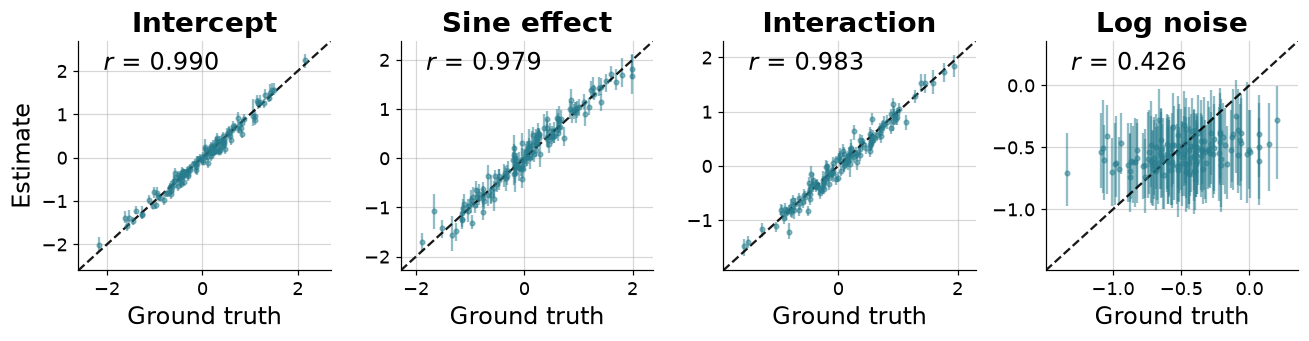

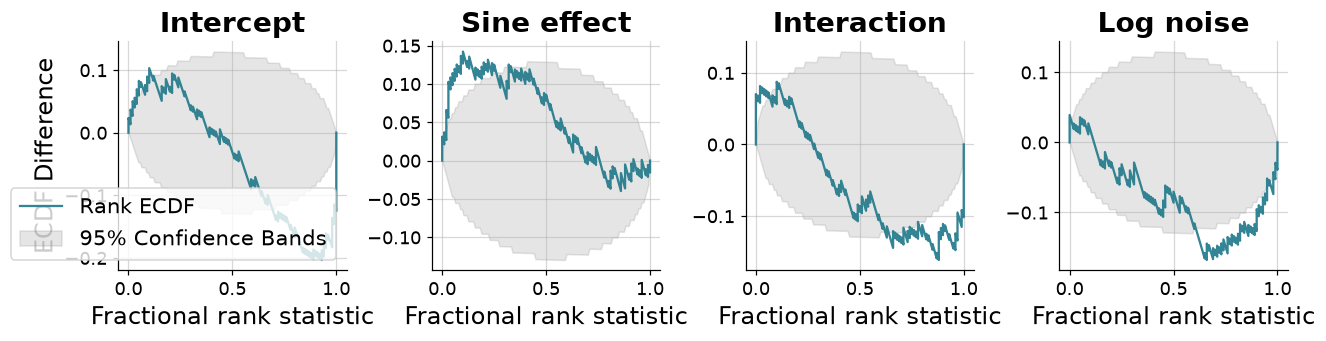

In [16]:
pfn_samples = tabpfn_posterior(test_raw["y"], num_samples=100)

_ = bf.diagnostics.recovery(
    estimates=pfn_samples,
    targets=test_raw,
    variable_keys=REGRESSION_PARAMETER_NAMES,
    variable_names=["Intercept", "Sine effect", "Interaction", "Log noise"],
    uncertainty_agg_kwargs={"prob": 0.9}, color="#287D8E",
    num_col=4,
    figsize=(12, 3.2),
    markersize=3,
)

_ = bf.diagnostics.calibration_ecdf(
    estimates=pfn_samples, 
    targets=test_raw,
    variable_keys=REGRESSION_PARAMETER_NAMES,
    variable_names=["Intercept", "Sine effect", "Interaction", "Log noise"],
    difference=True, 
    num_col=4, figsize=(12, 3.2), 
    rank_ecdf_color="#287D8E",
)

The direct TabPFN inference recovers the intercept, sine effect, and interaction term well in this experiment. However, recovery of the log-noise parameter is much weaker and may need more context simulations. The rank ECDF also shows visible miscalibration, especially for the interaction and log noise. 

Thus, in-context autoregressive prediction does not automatically guarantee an accurate posterior.

### The same observation

The observed response vector from the first example is now the TabPFN query row. No embedding or BayesFlow network is involved: the sequential predictive distributions described above produce the parameter draws directly.

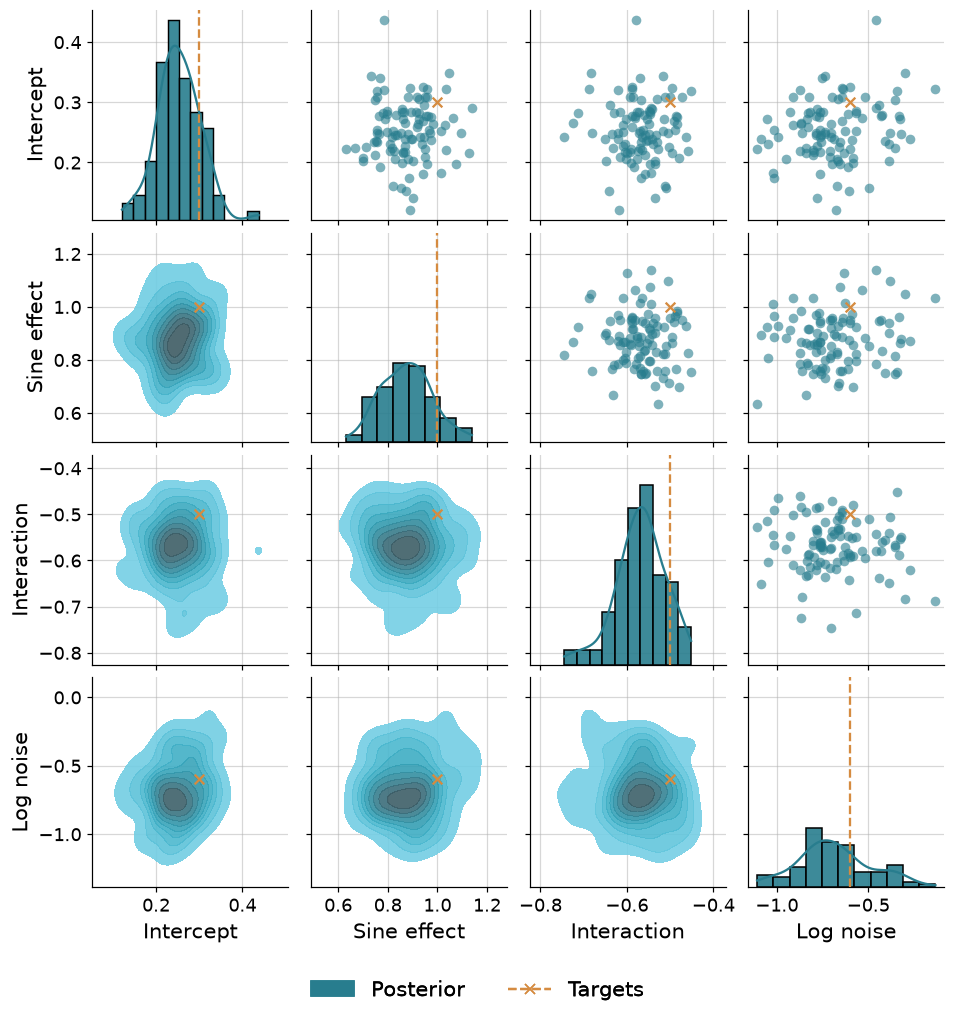

In [17]:
pfn_observed_samples = tabpfn_posterior(observed_y, num_samples=100)

_ = bf.diagnostics.pairs_posterior(
    estimates=pfn_observed_samples,
    targets=observed_parameters,
    variable_keys=REGRESSION_PARAMETER_NAMES,
    variable_names=["Intercept", "Sine effect", "Interaction", "Log noise"],
    post_color="#287D8E", target_color="#D58B40",
    height=2.2, place_legend_below=True,
)

The posterior for this one simulated observation is plausible, but much broader than the one obtained with a custom BayesFlow head (as expected given the global recovery results). Moreover, repeated autoregressive prediction calls become expensive as the number of parameters, query datasets, or posterior draws grows. This tradeoff can be attractive for small simulation budgets and a few observations, but it is definitely not an amortized solution for large numbers of observed datasets.